# Project: Salary Prediction with PyTorch
Item	Description:

Problem type	Supervised learning Task	Regression Input feature X	YearsExperience Target y	Salary Model	Simple Linear Regression Loss	Mean Squared Error Optimizer	Stochastic Gradient Descent Metrics	MAE, RMSE and R²
Dataset	Salary Dataset on Kaggle

The dataset contains 30 observations and the columns YearsExperience and Salary.

#Check PyTorch

In [2]:
import torch
print("PyTorch version", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version 2.11.0+cu128
GPU available: True


#Download the Kaggle dataset directly

In [3]:
!pip install -q kagglehub

In [4]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "abhishek14398/salary-dataset-simple-linear-regression"

)

print("Dataset folder:", dataset_path)
print("Files:", os.listdir(dataset_path))

100%|██████████| 457/457 [00:00<00:00, 766kB/s]

Extracting files...
Dataset folder: /root/.cache/kagglehub/datasets/abhishek14398/salary-dataset-simple-linear-regression/versions/1
Files: ['Salary_dataset.csv']


#Load the dataset

In [5]:
import pandas as pd

csv_path = os.path.join(
    dataset_path,
    "Salary_dataset.csv"
)

df = pd.read_csv(csv_path)

print(df.head())
print("\n Dataset shape:", df.shape)
print("\n Columns", df.columns.tolist())

   Unnamed: 0  YearsExperience   Salary
0           0              1.2  39344.0
1           1              1.4  46206.0
2           2              1.6  37732.0
3           3              2.1  43526.0
4           4              2.3  39892.0

 Dataset shape: (30, 3)

 Columns ['Unnamed: 0', 'YearsExperience', 'Salary']


#Remove the unnecessary column

In [6]:
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print(df.head())

   YearsExperience   Salary
0              1.2  39344.0
1              1.4  46206.0
2              1.6  37732.0
3              2.1  43526.0
4              2.3  39892.0


#Inspect the data

In [7]:
print("First five rows")
display(df.head())

print("\n Dataset information:")
df.info()

print("\n Missing values:")
display(df.isnull().sum())

print("\n Duplicates rows", df.duplicated().sum())

print("\n Statistical summary:")
display(df.describe())

First five rows


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0



 Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes

 Missing values:


,0
YearsExperience,0
Salary,0



 Duplicates rows 0

 Statistical summary:


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.413333,76004.000000
std,2.837888,27414.429785
min,1.200000,37732.000000
25%,3.300000,56721.750000
50%,4.800000,65238.000000
75%,7.800000,100545.750000
max,10.600000,122392.000000


##count: Number of values → 30 employees

##mean: Average → 5.41 years, $76,004 salary

##std: How spread out the values are → 2.84 years, $27,414

## min: Smallest value → 1.2 years, $37,732

## 25%: 25% of values are below this → 3.3 years, $56,721.75

## 50%: Median/middle value → 4.8 years, $65,238

## 75%: 75% of values are below this → 7.8 years, $100,545.75

## max: Largest value → 10.6 years, $122,392

#Visualize the relationship

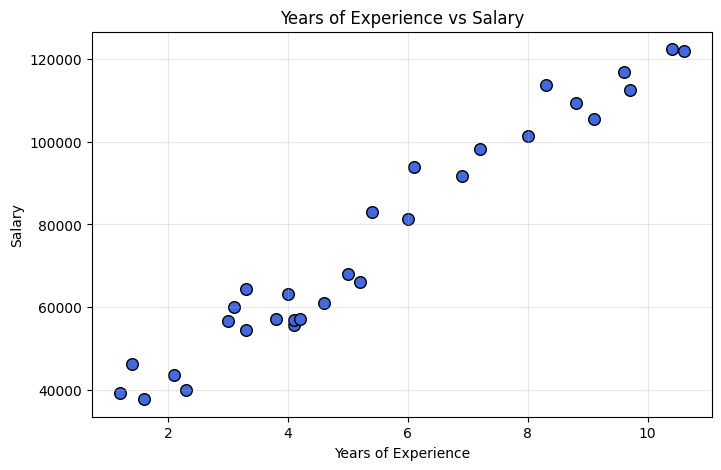

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["YearsExperience"],
    df["Salary"],
    color="royalblue",
    edgecolor="black",
    s=70
)

plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.grid(alpha=0.3)
plt.show()

In [9]:
correlation = df["YearsExperience"].corr(
    df["Salary"]
)

print("Correlation:", correlation)

Correlation: 0.9782416184887599


#Prepare the Data for PyTorch

In [10]:
import random
import numpy as np
import torch

from sklearn.model_selection import train_test_split

In [11]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

#Define the feature and target

In [12]:
X = df[["YearsExperience"]].to_numpy(
    dtype=np.float32
)

y = df[["Salary"]].to_numpy(
    dtype=np.float32
)

In [13]:
print("First five X values:")
print(X[:5])

print("\nFirst five y values:")
print(y[:5])

print("\nX shape:", X.shape)
print("y shape:", y.shape)

First five X values:
[[1.2]
 [1.4]
 [1.6]
 [2.1]
 [2.3]]

First five y values:
[[39344.]
 [46206.]
 [37732.]
 [43526.]
 [39892.]]

X shape: (30, 1)
y shape: (30, 1)


##Understanding X and y

| Variable | Meaning             | Role          |
| -------- | ------------------- | ------------- |
| `X`      | Years of experience | Input feature |
| `y`      | Salary              | Target/output |


##We used:

###df[["YearsExperience"]]

instead of:

###df["YearsExperience"]

Double brackets keep the shape two-dimensional:

(30, 1)

This shape works correctly with PyTorch’s nn.Linear.

In [14]:
X_train_np, X_test_np,y_train_np, y_test_np = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED
)

In [15]:
print("X_train shape:", X_train_np.shape)
print("X_test shape:", X_test_np.shape)

print("y_train shape:", y_train_np.shape)
print("y_test shape:", y_test_np.shape)

X_train shape: (24, 1)
X_test shape: (6, 1)
y_train shape: (24, 1)
y_test shape: (6, 1)


##Why split the data?

Training data: used to learn the weight and bias.
Testing data: used to evaluate the model on unseen examples.

The model must never train on test data.

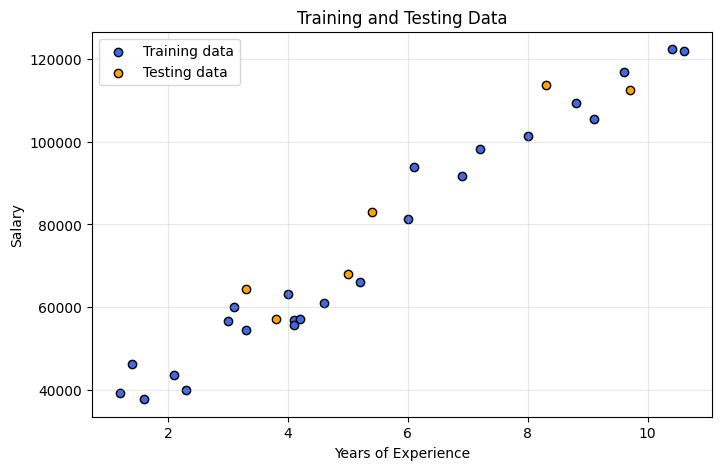

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    X_train_np,
    y_train_np,
    color="royalblue",
    edgecolor="black",
    label="Training data"
)

plt.scatter(
    X_test_np,
    y_test_np,
    color="orange",
    edgecolor="black",
    label="Testing data"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Training and Testing Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##The blue points train the model. The orange points test it.

#Convert NumPy arrays to PyTorch tensors

In [17]:
X_train = torch.tensor(
    X_train_np,
    dtype=torch.float32
)

X_test = torch.tensor(
    X_test_np,
    dtype=torch.float32
)

y_train = torch.tensor(
    y_train_np,
    dtype=torch.float32
)

y_test = torch.tensor(
    y_test_np,
    dtype=torch.float32
)

In [18]:
print("X_train:")
print(X_train[:5])

print("\nTensor information:")
print("Shape:", X_train.shape)
print("Data type:", X_train.dtype)
print("Device:", X_train.device)

X_train:
tensor([[10.4000],
        [ 8.8000],
        [ 4.1000],
        [ 1.2000],
        [ 2.3000]])

Tensor information:
Shape: torch.Size([24, 1])
Data type: torch.float32
Device: cpu


##Why tensors?

PyTorch models operate on tensors. Tensors support:

Mathematical operations
Automatic differentiation
Gradient calculation
CPU and GPU computation

#Calculate training statistics

- Salary values are much larger than experience values:

- Experience: approximately 1–11

- Salary: approximately 39,000–122,000

Standardization makes model training more stable.

Calculate mean and standard deviation using only training data:

In [19]:
x_mean = X_train.mean(dim=0, keepdim=True)
x_std = X_train.std(dim=0, keepdim=True)

y_mean = y_train.mean(dim=0, keepdim=True)
y_std = y_train.std(dim=0, keepdim=True)

In [20]:
print("Experience mean:", x_mean.item())
print("Experience standard deviation:", x_std.item())

print("\nSalary mean:", y_mean.item())
print("Salary standard deviation:", y_std.item())

Experience mean: 5.287499904632568
Experience standard deviation: 2.943129539489746

Salary mean: 74208.625
Salary standard deviation: 28240.734375


In [21]:
X_train_scaled = (
    X_train - x_mean
) / x_std

X_test_scaled = (
    X_test - x_mean
) / x_std

y_train_scaled = (
    y_train - y_mean
) / y_std

y_test_scaled = (
    y_test - y_mean
) / y_std

- Notice that test data uses the training mean and standard deviation.

In [22]:
X_test_scaled = (X_test - x_mean) / x_std

In [23]:
print("Original training inputs:")
print(X_train[:5])

print("\nStandardized training inputs:")
print(X_train_scaled[:5])

print("\nOriginal training targets:")
print(y_train[:5])

print("\nStandardized training targets:")
print(y_train_scaled[:5])


Original training inputs:
tensor([[10.4000],
        [ 8.8000],
        [ 4.1000],
        [ 1.2000],
        [ 2.3000]])

Standardized training inputs:
tensor([[ 1.7371],
        [ 1.1935],
        [-0.4035],
        [-1.3888],
        [-1.0151]])

Original training targets:
tensor([[122392.],
        [109432.],
        [ 56958.],
        [ 39344.],
        [ 39892.]])

Standardized training targets:
tensor([[ 1.7062],
        [ 1.2473],
        [-0.6108],
        [-1.2346],
        [-1.2151]])


In [24]:
print(
    "Scaled X mean:",
    X_train_scaled.mean().item()
)

print(
    "Scaled X standard deviation:",
    X_train_scaled.std().item()
)

print(
    "Scaled y mean:",
    y_train_scaled.mean().item()
)

print(
    "Scaled y standard deviation:",
    y_train_scaled.std().item()
)

Scaled X mean: 2.359350581571107e-08
Scaled X standard deviation: 1.0
Scaled y mean: -1.2417634032146907e-08
Scaled y standard deviation: 0.9999999403953552


In [25]:
print("Data preparation completed.")

print("\nTraining input:", X_train_scaled.shape)
print("Training target:", y_train_scaled.shape)

print("Testing input:", X_test_scaled.shape)
print("Testing target:", y_test_scaled.shape)

print("\nInput datatype:", X_train_scaled.dtype)
print("Target datatype:", y_train_scaled.dtype)

Data preparation completed.

Training input: torch.Size([24, 1])
Training target: torch.Size([24, 1])
Testing input: torch.Size([6, 1])
Testing target: torch.Size([6, 1])

Input datatype: torch.float32
Target datatype: torch.float32


##What you learned in this stage

You should now understand:

- X is the input feature.
- y is the target.
- Training data teaches the model.
- Test data evaluates the model.
- PyTorch models require tensors.
- Regression tensors should use float32.
- nn.Linear(1, 1) expects the shape [number_of_samples, 1].
- Standardization stabilizes gradient descent.
- Scaling values must be calculated from training data only.
- Predictions must later be converted back to the original salary scale.

#Build and Train the PyTorch Model

Input → Forward pass → Prediction → MSE loss
→ Backpropagation → Update weight and bias

In [26]:
import torch
from torch import nn

In [27]:
torch.manual_seed(42)

##Create the linear-regression model

In [28]:
class SalaryLinearRegression(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Linear(
            in_features=1,
            out_features=1
        )

    def forward(self, x):
        return self.linear(x)

In [29]:
model = SalaryLinearRegression()

print(model)

SalaryLinearRegression(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)


#Inspect the initial parameters

In [30]:
print("Initial model parameters:")

for name, parameter in model.named_parameters():
    print(name, parameter.data)

Initial model parameters:
linear.weight tensor([[0.7645]])
linear.bias tensor([0.8300])


In [31]:
print(
    "Initial weight:",
    model.linear.weight.item()
)

print(
    "Initial bias:",
    model.linear.bias.item()
)

Initial weight: 0.7645385265350342
Initial bias: 0.8300079107284546


#Make predictions before training

In [32]:
model.eval()

with torch.inference_mode():
    initial_predictions = model(X_train_scaled)

In [33]:
print("Initial predictions:")
print(initial_predictions[:5])

print("\nActual standardized salaries:")
print(y_train_scaled[:5])

Initial predictions:
tensor([[ 2.1581],
        [ 1.7425],
        [ 0.5215],
        [-0.2318],
        [ 0.0539]])

Actual standardized salaries:
tensor([[ 1.7062],
        [ 1.2473],
        [-0.6108],
        [-1.2346],
        [-1.2151]])


#Define the loss function

In [34]:
loss_function = nn.MSELoss()

In [35]:
initial_loss = loss_function(
    initial_predictions,
    y_train_scaled
)

print("Initial loss:", initial_loss.item())

Initial loss: 0.7682604789733887


A loss function measures how wrong a machine learning model's predictions are by comparing them to the true values. An optimizer uses that error feedback to change the model's internal weights and biases so future guesses become more accurate.

#Define the optimizer

In [36]:
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

The learning rate controls the update size:

Too small: learning becomes slow.

Too large: loss may jump or become nan.

Suitable value: loss gradually decreases.

#Understand one training step

Before running the full training loop, understand these five operations:

## 1. Clear old gradients
optimizer.zero_grad()

##2. Make predictions
predictions = model(X_train_scaled)

## 3. Calculate loss
loss = loss_function(
    predictions,
    y_train_scaled
)

## 4. Calculate gradients
loss.backward()

## 5. Update weight and bias
optimizer.step()

In [37]:
epochs = 500
training_losses = []

for epoch in range(epochs + 1):
    # Put the model in training mode
    model.train()

    # 1. Clear gradients from the previous iteration
    optimizer.zero_grad()

    # 2. Forward propagation
    predictions = model(X_train_scaled)

    # 3. Calculate training loss
    loss = loss_function(
        predictions,
        y_train_scaled
    )

    # 4. Backpropagation
    loss.backward()

    # 5. Update weight and bias
    optimizer.step()

    # Store loss as a normal Python number
    training_losses.append(loss.item())

    # Display progress every 50 epochs
    if epoch % 50 == 0:
        print(
            f"Epoch: {epoch:3d} | "
            f"Training loss: {loss.item():.6f}"
        )

Epoch:   0 | Training loss: 0.768260
Epoch:  50 | Training loss: 0.034003
Epoch: 100 | Training loss: 0.033982
Epoch: 150 | Training loss: 0.033982
Epoch: 200 | Training loss: 0.033982
Epoch: 250 | Training loss: 0.033982
Epoch: 300 | Training loss: 0.033982
Epoch: 350 | Training loss: 0.033982
Epoch: 400 | Training loss: 0.033982
Epoch: 450 | Training loss: 0.033982
Epoch: 500 | Training loss: 0.033982


#Inspect the learned parameters

In [38]:
print("Learned standardized parameters:")

print(
    "Weight:",
    model.linear.weight.item()
)

print(
    "Bias:",
    model.linear.bias.item()
)

Learned standardized parameters:
Weight: 0.9821097254753113
Bias: -3.158621808552198e-08


#Plot the training loss

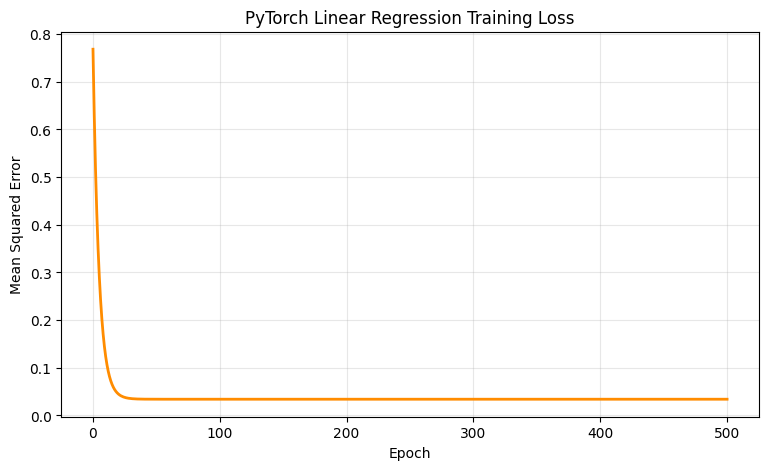

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    training_losses,
    color="darkorange",
    linewidth=2
)

plt.title("PyTorch Linear Regression Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(alpha=0.3)
plt.show()

#Compare initial and final loss

In [40]:
model.eval()

with torch.inference_mode():
    final_train_predictions = model(
        X_train_scaled
    )

    final_training_loss = loss_function(
        final_train_predictions,
        y_train_scaled
    )

In [41]:
print(
    f"Initial loss: "
    f"{initial_loss.item():.6f}"
)

print(
    f"Final training loss: "
    f"{final_training_loss.item():.6f}"
)

Initial loss: 0.768260
Final training loss: 0.033982


#Check prediction shapes

In [42]:
print(
    "Predictions shape:",
    final_train_predictions.shape
)

print(
    "Targets shape:",
    y_train_scaled.shape
)

Predictions shape: torch.Size([24, 1])
Targets shape: torch.Size([24, 1])


#Evaluate the Model

Test prediction → Reverse scaling → Metrics
→ Learned equation → Regression line → New predictions

In [43]:
model.eval()

with torch.inference_mode():
    test_predictions_scaled = model(
        X_test_scaled
    )

In [44]:
print("Predicted standardized salaries:")
print(test_predictions_scaled)

print("\nActual standardized salaries:")
print(y_test_scaled)

Predicted standardized salaries:
tensor([[ 1.4724],
        [-0.0959],
        [ 1.0053],
        [ 0.0375],
        [-0.6632],
        [-0.4964]])

Actual standardized salaries:
tensor([[ 1.3607],
        [-0.2220],
        [ 1.4024],
        [ 0.3145],
        [-0.3457],
        [-0.6026]])


#Convert predictions to real salaries

In [45]:
test_predictions = (
    test_predictions_scaled * y_std
) + y_mean

In [46]:
print("Predicted real salaries:")
print(test_predictions)

print("\nActual real salaries:")
print(y_test)

Predicted real salaries:
tensor([[115791.1875],
        [ 71499.2812],
        [102597.8594],
        [ 75268.8047],
        [ 55478.7969],
        [ 60190.7031]])

Actual real salaries:
tensor([[112636.],
        [ 67939.],
        [113813.],
        [ 83089.],
        [ 64446.],
        [ 57190.]])


#Create the evaluation metrics

In [47]:
def calculate_regression_metrics(y_true, y_pred):
    errors = y_true - y_pred

    mae = torch.mean(torch.abs(errors))
    mse = torch.mean(errors ** 2)
    rmse = torch.sqrt(mse)

    residual_sum_of_squares = torch.sum(
        (y_true - y_pred) ** 2
    )

    total_sum_of_squares = torch.sum(
        (y_true - torch.mean(y_true)) ** 2
    )

    r2 = 1 - (
        residual_sum_of_squares
        / total_sum_of_squares
    )

    return {
        "MAE": mae.item(),
        "MSE": mse.item(),
        "RMSE": rmse.item(),
        "R2": r2.item()
    }

In [48]:
test_metrics = calculate_regression_metrics(
    y_test,
    test_predictions
)

print("Test results:")

for metric_name, metric_value in test_metrics.items():
    print(
        f"{metric_name}: "
        f"{metric_value:,.4f}"
    )

Test results:
MAE: 6,286.4517
MSE: 49,830,096.0000
RMSE: 7,059.0435
R2: 0.9024


#Compare training and testing performance

In [49]:
model.eval()

with torch.inference_mode():
    train_predictions_scaled = model(
        X_train_scaled
    )

    train_predictions = (
        train_predictions_scaled * y_std
    ) + y_mean

In [51]:
train_metrics = calculate_regression_metrics(
    y_train,
    train_predictions
)

test_metrics = calculate_regression_metrics(
    y_test,
    test_predictions
)

In [52]:
import pandas as pd

metrics_table = pd.DataFrame({
    "Training": train_metrics,
    "Testing": test_metrics
})

display(metrics_table)

,Training,Testing
MAE,4.221048e+03,6.286452e+03
MSE,2.710225e+07,4.983010e+07
RMSE,5.205982e+03,7.059043e+03
R2,9.645402e-01,9.024462e-01


Interpretation:

Similar training and testing results suggest good generalization.
Excellent training but poor testing suggests overfitting.
Poor results on both suggest underfitting or a data/model problem.

Because this dataset contains only 30 observations and 6 test records, the test results can change noticeably with a different split.

#Compare actual and predicted values

In [53]:
results = pd.DataFrame({
    "YearsExperience": (
        X_test.squeeze().numpy()
    ),
    "ActualSalary": (
        y_test.squeeze().numpy()
    ),
    "PredictedSalary": (
        test_predictions.squeeze().numpy()
    )
})

results["Error"] = (
    results["ActualSalary"]
    - results["PredictedSalary"]
)

results["AbsoluteError"] = abs(
    results["Error"]
)

results = results.sort_values(
    by="YearsExperience"
).reset_index(drop=True)

display(results)

,YearsExperience,ActualSalary,PredictedSalary,Error,AbsoluteError
0,3.3,64446.0,55478.796875,8967.203125,8967.203125
1,3.8,57190.0,60190.703125,-3000.703125,3000.703125
2,5.0,67939.0,71499.281250,-3560.281250,3560.281250
3,5.4,83089.0,75268.804688,7820.195312,7820.195312
4,8.3,113813.0,102597.859375,11215.140625,11215.140625
5,9.7,112636.0,115791.187500,-3155.187500,3155.187500


Interpretation:

- Positive error: model predicted too low.
- Negative error: model predicted too high.
- Absolute error: size of error without considering direction.

#Recover the original equation

In [54]:
with torch.inference_mode():
    scaled_weight = model.linear.weight.squeeze()
    scaled_bias = model.linear.bias.squeeze()

    original_slope = (
        y_std.squeeze()
        * scaled_weight
        / x_std.squeeze()
    )

    original_intercept = (
        y_mean.squeeze()
        + y_std.squeeze() * scaled_bias
        - original_slope * x_mean.squeeze()
    )

In [55]:
print(
    "Original slope:",
    f"{original_slope.item():,.2f}"
)

print(
    "Original intercept:",
    f"{original_intercept.item():,.2f}"
)

Original slope: 9,423.81
Original intercept: 24,380.22


In [56]:
print(
    "\nLearned equation:\n"
    f"Salary = "
    f"{original_slope.item():,.2f} "
    f"× YearsExperience + "
    f"{original_intercept.item():,.2f}"
)


Learned equation:
Salary = 9,423.81 × YearsExperience + 24,380.22


#Draw the regression line

In [57]:
x_line = torch.linspace(
    start=float(X.min()),
    end=float(X.max()),
    steps=100
).reshape(-1, 1)

In [58]:
with torch.inference_mode():
    x_line_scaled = (
        x_line - x_mean
    ) / x_std

    y_line_scaled = model(
        x_line_scaled
    )

    y_line = (
        y_line_scaled * y_std
    ) + y_mean

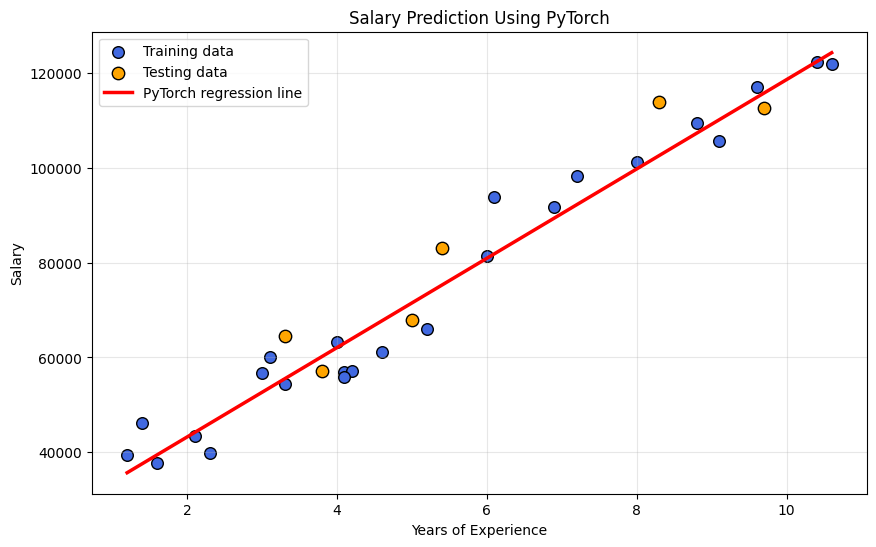

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train.squeeze().numpy(),
    y_train.squeeze().numpy(),
    color="royalblue",
    edgecolor="black",
    s=70,
    label="Training data"
)

plt.scatter(
    X_test.squeeze().numpy(),
    y_test.squeeze().numpy(),
    color="orange",
    edgecolor="black",
    s=80,
    label="Testing data"
)

plt.plot(
    x_line.squeeze().numpy(),
    y_line.squeeze().numpy(),
    color="red",
    linewidth=2.5,
    label="PyTorch regression line"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary Prediction Using PyTorch")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [60]:
def predict_salary(years_of_experience):
    new_experience = torch.tensor(
        [[years_of_experience]],
        dtype=torch.float32
    )

    new_experience_scaled = (
        new_experience - x_mean
    ) / x_std

    model.eval()

    with torch.inference_mode():
        predicted_salary_scaled = model(
            new_experience_scaled
        )

        predicted_salary = (
            predicted_salary_scaled * y_std
        ) + y_mean

    return predicted_salary.item()

In [61]:
experience = 7.5

salary = predict_salary(experience)

print(
    f"Experience: {experience} years"
)

print(
    f"Predicted salary: {salary:,.2f}"
)

Experience: 7.5 years
Predicted salary: 95,058.81


In [62]:
experience_values = [
    2.0,
    5.0,
    7.5,
    10.0
]

for experience in experience_values:
    salary = predict_salary(experience)

    print(
        f"{experience:4.1f} years"
        f" → {salary:,.2f}"
    )

 2.0 years → 43,227.84
 5.0 years → 71,499.28
 7.5 years → 95,058.81
10.0 years → 118,618.34


#Analyze residuals

In [63]:
residuals = (
    y_test - test_predictions
)

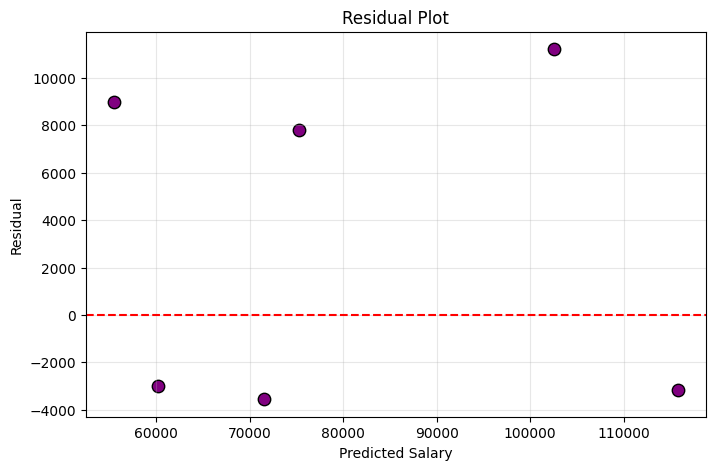

In [64]:
plt.figure(figsize=(8, 5))

plt.scatter(
    test_predictions.squeeze().numpy(),
    residuals.squeeze().numpy(),
    color="purple",
    edgecolor="black",
    s=80
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Salary")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()

A good residual plot should show errors scattered around zero without a clear pattern.

However, this test set has only six points, so do not make strong statistical conclusions from this plot.


#Stage completed

You have now completed the main ML pipeline:

Load data
→ Explore data
→ Split data
→ Convert to tensors
→ Standardize
→ Build model
→ Train
→ Evaluate
→ Visualize
→ Predict

#Save, Load and Download the Model

In [71]:
checkpoint = {
    # Trained weight and bias
    "model_state_dict": model.state_dict(),

    # Preprocessing statistics
    "x_mean": x_mean,
    "x_std": x_std,
    "y_mean": y_mean,
    "y_std": y_std,

    # Model configuration
    "input_features": 1,
    "output_features": 1,

    # Training information
    "epochs": epochs,
    "learning_rate": 0.05,
    "random_seed": SEED,

    # Evaluation results
    "train_metrics": train_metrics,
    "test_metrics": test_metrics,

    # Dataset information
    "feature_name": "YearsExperience",
    "target_name": "Salary"
}

In [72]:
checkpoint = {
    # Trained weight and bias
    "model_state_dict": model.state_dict(),

    # Preprocessing statistics
    "x_mean": x_mean,
    "x_std": x_std,
    "y_mean": y_mean,
    "y_std": y_std,

    # Model configuration
    "input_features": 1,
    "output_features": 1,

    # Training information
    "epochs": epochs,
    "learning_rate": 0.05,
    "random_seed": SEED,

    # Evaluation results
    "train_metrics": train_metrics,
    "test_metrics": test_metrics,

    # Dataset information
    "feature_name": "YearsExperience",
    "target_name": "Salary"
}

In [74]:
import os
import torch

# Create the checkpoint again
checkpoint = {
    "model_state_dict": model.state_dict(),
    "x_mean": x_mean,
    "x_std": x_std,
    "y_mean": y_mean,
    "y_std": y_std,
    "input_features": 1,
    "output_features": 1,
    "epochs": epochs,
    "learning_rate": 0.05,
    "random_seed": SEED,
    "train_metrics": train_metrics,
    "test_metrics": test_metrics,
    "feature_name": "YearsExperience",
    "target_name": "Salary"
}

# Define the missing variable
checkpoint_path = "/content/salary_linear_regression_checkpoint.pth"

# Save the checkpoint
torch.save(checkpoint, checkpoint_path)

# Verify it
print("Checkpoint saved:", checkpoint_path)
print("File exists:", os.path.exists(checkpoint_path))
print("File size:", os.path.getsize(checkpoint_path), "bytes")

Checkpoint saved: /content/salary_linear_regression_checkpoint.pth
File exists: True
File size: 3749 bytes


#Create a completely new model

In [75]:
loaded_model = SalaryLinearRegression()

print("New model before loading:")
print(loaded_model.state_dict())

New model before loading:
OrderedDict({'linear.weight': tensor([[-0.2191]]), 'linear.bias': tensor([0.2018])})


#Load the checkpoint

In [76]:
loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

In [77]:
import os

print(
    "File exists:",
    os.path.exists(checkpoint_path)
)

print(
    "File size:",
    os.path.getsize(checkpoint_path),
    "bytes"
)

File exists: True
File size: 3749 bytes


In [78]:
loaded_model.load_state_dict(
    loaded_checkpoint["model_state_dict"]
)

loaded_model.eval()

SalaryLinearRegression(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)

In [79]:
loaded_x_mean = loaded_checkpoint["x_mean"]
loaded_x_std = loaded_checkpoint["x_std"]

loaded_y_mean = loaded_checkpoint["y_mean"]
loaded_y_std = loaded_checkpoint["y_std"]

#Create a prediction function for the loaded model

In [80]:
def predict_with_loaded_model(years_of_experience):
    input_tensor = torch.tensor(
        [[years_of_experience]],
        dtype=torch.float32
    )

    # Apply the saved input preprocessing
    input_scaled = (
        input_tensor - loaded_x_mean
    ) / loaded_x_std

    loaded_model.eval()

    with torch.inference_mode():
        prediction_scaled = loaded_model(
            input_scaled
        )

        # Convert back to the real salary scale
        prediction = (
            prediction_scaled * loaded_y_std
        ) + loaded_y_mean

    return prediction.item()

In [81]:
experience = 7.5

loaded_prediction = predict_with_loaded_model(
    experience
)

print(
    f"Experience: {experience} years"
)

print(
    f"Predicted salary: "
    f"{loaded_prediction:,.2f}"
)

Experience: 7.5 years
Predicted salary: 95,058.81


#Verify that both models agree

In [82]:
original_prediction = predict_salary(7.5)

loaded_prediction = predict_with_loaded_model(
    7.5
)

print(
    "Original model prediction:",
    f"{original_prediction:,.4f}"
)

print(
    "Loaded model prediction:",
    f"{loaded_prediction:,.4f}"
)

Original model prediction: 95,058.8125
Loaded model prediction: 95,058.8125


In [83]:
predictions_match = np.isclose(
    original_prediction,
    loaded_prediction,
    atol=1e-4
)

print(
    "Predictions match:",
    predictions_match
)

Predictions match: True


#Save the test results

In [84]:
results_path = (
    "/content/salary_test_predictions.csv"
)

results.to_csv(
    results_path,
    index=False
)

print("Results saved:", results_path)

Results saved: /content/salary_test_predictions.csv


In [85]:
saved_results = pd.read_csv(results_path)

display(saved_results)

,YearsExperience,ActualSalary,PredictedSalary,Error,AbsoluteError
0,3.3,64446.0,55478.797,8967.2030,8967.2030
1,3.8,57190.0,60190.703,-3000.7031,3000.7031
2,5.0,67939.0,71499.280,-3560.2812,3560.2812
3,5.4,83089.0,75268.805,7820.1953,7820.1953
4,8.3,113813.0,102597.860,11215.1410,11215.1410
5,9.7,112636.0,115791.190,-3155.1875,3155.1875


#Save a project summary

In [86]:
import json

project_summary = {
    "project": "Salary Prediction with PyTorch",
    "algorithm": "Simple Linear Regression",
    "feature": "YearsExperience",
    "target": "Salary",
    "training_samples": len(X_train),
    "testing_samples": len(X_test),
    "epochs": epochs,
    "learning_rate": 0.05,
    "equation": (
        f"Salary = "
        f"{original_slope.item():.2f} × "
        f"YearsExperience + "
        f"{original_intercept.item():.2f}"
    ),
    "test_mae": test_metrics["MAE"],
    "test_rmse": test_metrics["RMSE"],
    "test_r2": test_metrics["R2"]
}

summary_path = "/content/project_summary.json"

with open(summary_path, "w") as file:
    json.dump(
        project_summary,
        file,
        indent=4
    )

print("Summary saved:", summary_path)

Summary saved: /content/project_summary.json


In [87]:
with open(summary_path, "r") as file:
    print(file.read())

{
    "project": "Salary Prediction with PyTorch",
    "algorithm": "Simple Linear Regression",
    "feature": "YearsExperience",
    "target": "Salary",
    "training_samples": 24,
    "testing_samples": 6,
    "epochs": 500,
    "learning_rate": 0.05,
    "equation": "Salary = 9423.81 \u00d7 YearsExperience + 24380.22",
    "test_mae": 6286.45166015625,
    "test_rmse": 7059.04345703125,
    "test_r2": 0.9024461507797241
}


#Save files permanently to Google Drive

In [89]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [90]:
drive_project_folder = (
    "/content/drive/MyDrive/"
    "ML_Projects/"
    "Salary_Linear_Regression"
)

os.makedirs(
    drive_project_folder,
    exist_ok=True
)

print(drive_project_folder)

/content/drive/MyDrive/ML_Projects/Salary_Linear_Regression


In [91]:
drive_checkpoint_path = os.path.join(
    drive_project_folder,
    "salary_linear_regression_checkpoint.pth"
)

torch.save(
    checkpoint,
    drive_checkpoint_path
)

In [92]:
drive_results_path = os.path.join(
    drive_project_folder,
    "salary_test_predictions.csv"
)

results.to_csv(
    drive_results_path,
    index=False
)

In [93]:
drive_summary_path = os.path.join(
    drive_project_folder,
    "project_summary.json"
)

with open(drive_summary_path, "w") as file:
    json.dump(
        project_summary,
        file,
        indent=4
    )

In [94]:
print("Saved files:")

for file_name in os.listdir(drive_project_folder):
    print("-", file_name)

Saved files:
- salary_linear_regression_checkpoint.pth
- salary_test_predictions.csv
- project_summary.json


#Project status

You have completed:

Problem definition

→ Dataset loading

→ Data exploration

→ Visualization

→ Train/test split

→ Tensor conversion

→ Standardization

→ Model creation

→ MSE loss

→ SGD optimizer

→ Training

→ Evaluation

→ Regression metrics

→ New predictions

→ Model saving

→ Model loading

→ Verification